In [1]:
# ============================================================
# CELL 1: INSTALLATION OF REQUIRED LIBRARIES
# ============================================================
# PROJECT PURPOSE:
# This project uses deep learning to classify breast
# histopathology images into benign and malignant categories.
#
# We need libraries for:
# 1. Image loading and preprocessing.
# 2. CNN and ECA-CNN construction.
# 3. Model training using gradient descent.
# 4. Dataset splitting and classification metrics.
# 5. Graphs, tables and Grad-CAM visualization.
#
# RESEARCH CONNECTION:
# This is an implementation setup cell. It does not implement
# the ECSAnet baseline architecture itself.
#
# FUNCTIONALITY:
# %pip installs the libraries into the Python environment
# associated with the current Jupyter notebook kernel.
# Run this cell when setting up the environment, not every
# time you restart the notebook if the packages are installed.

#%pip install torch torchvision scikit-learn pandas numpy matplotlib pillow

In [2]:
# ============================================================
# CELL 2: IMPORTS, RANDOM SEEDS AND COMPUTING DEVICE
# ============================================================
# PROJECT PURPOSE:
# Prepare the programming environment before processing
# BreakHis images or constructing neural networks.
#
# FUNCTIONALITY:
# - pathlib and os help navigate dataset folders.
# - re helps extract patient and magnification metadata.
# - random and numpy support reproducible random operations.
# - pandas stores dataset metadata in tabular form.
# - matplotlib creates training and evaluation graphs.
# - PIL opens histopathology images.
# - torch implements neural networks and training.
# - torchvision provides image preprocessing operations.
# - sklearn provides dataset splitting and evaluation metrics.
#
# RESEARCH CONNECTION:
# These are standard research implementation tools. The
# baseline-paper connection is through later model and
# evaluation cells, not through these imports.

import os
import re
import random
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    classification_report
)

# Set a common seed for Python, NumPy and PyTorch.
# This makes random operations more reproducible, although
# some GPU operations may still introduce small variations.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Check whether a CUDA-enabled GPU is available.
# If it is available, model calculations can use the GPU.
# Otherwise, the notebook automatically uses the CPU.
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Selected computing device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
Selected computing device: cpu
CUDA available: False


In [3]:
# ============================================================
# CELL 3: DATASET PATH AND EXPERIMENT CONFIGURATION
# ============================================================
# PROJECT PURPOSE:
# Tell the notebook where the downloaded BreakHis dataset is
# located and define common experimental parameters.
#
# IMPORTANT:
# Download and extract BreakHis before running the notebook.
# Update DATA_ROOT to the actual directory on your computer.
#
# FUNCTIONALITY:
# - IMAGE_SIZE determines the spatial dimensions of model input.
# - BATCH_SIZE determines how many images are processed together.
# - EPOCHS determines the maximum number of training passes.
# - LEARNING_RATE controls the size of optimizer updates.
# - CLASS_NAMES gives readable names to numeric labels.
#
# The same main settings will be used for the plain CNN and
# ECA-CNN comparison to make the experiment more controlled.
#
# RESEARCH CONNECTION:
# BreakHis is also used in the selected baseline paper.
# However, matching the dataset alone does not reproduce
# that paper's architecture or complete experimental protocol.

DATA_ROOT = Path(
    r'C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis_v1\histology_slides\breast'
)

IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 0.001

CLASS_NAMES = {
    0: "Benign",
    1: "Malignant"
}

# Stop early if the supplied directory does not exist.
# This prevents the later cells from silently processing
# an empty or incorrect dataset location.
if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset folder does not exist: {DATA_ROOT}\n"
        "Edit DATA_ROOT in Cell 3 to match your extracted dataset."
    )

print("Dataset directory:", DATA_ROOT.resolve())
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Maximum training epochs:", EPOCHS)

Dataset directory: C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis_v1\histology_slides\breast
Image size: 224
Batch size: 32
Maximum training epochs: 10


In [4]:
# ============================================================
# CELL 4: IMAGE MANIFEST AND METADATA EXTRACTION
# ============================================================
# PROJECT PURPOSE:
# Build a table containing the image path, class label,
# patient identifier and magnification level for every image.
#
# WHY THIS IS NECESSARY:
# The neural network needs numeric labels to learn.
# Patient identifiers allow patient-wise data splitting.
# Magnification metadata allows us to evaluate the model
# separately at 40x, 100x, 200x and 400x where available.
#
# BREAKHIS FILE NAMING:
# Common filenames resemble:
# SOB_B_A-14-22549AB-40-001.png
#
# The regular expressions below assume a common BreakHis
# naming convention. They MUST be verified against the
# downloaded files before interpreting results.
#
# FUNCTIONALITY:
# 1. Search the dataset recursively for supported image files.
# 2. Infer benign/malignant from folder names.
# 3. Extract a candidate patient grouping identifier.
# 4. Extract the magnification level.
# 5. Store the resulting information in a pandas DataFrame.
#
# RESEARCH CONNECTION:
# This prepares the BreakHis data used by the baseline.
# Correct patient metadata is also important for avoiding
# leakage between training, validation and test sets.

records = []

# Common filename prefix before magnification and image sequence.
# This candidate grouping key must be checked against actual
# patient identifiers in the downloaded BreakHis documentation.
patient_pattern = re.compile(
    r"^(SOB_[BM]_[A-Z]+-\d+-[A-Z0-9]+)-"
)

# Identify the magnification field in common BreakHis filenames.
magnification_pattern = re.compile(
    r"-(40|100|200|400)-"
)

# Traverse nested directories and inspect every image file.
for image_path in DATA_ROOT.rglob("*"):

    # Ignore non-image files such as text documents and archives.
    if image_path.suffix.lower() not in {
        ".png", ".jpg", ".jpeg", ".bmp"
    }:
        continue

    # Combine directory names to identify the class folder.
    folder_text = " ".join(
        part.lower() for part in image_path.parts
    )

    # Assign numeric labels:
    # 0 = benign, 1 = malignant.
    if "benign" in folder_text:
        label = 0
    elif "malignant" in folder_text:
        label = 1
    else:
        # Do not guess a label when the class is unclear.
        continue

    # Extract the filename without its extension.
    filename = image_path.stem

    # Attempt to extract the patient grouping key.
    patient_match = patient_pattern.search(filename)

    # Attempt to extract magnification metadata.
    magnification_match = magnification_pattern.search(filename)

    # Skip filenames that do not match the assumed naming scheme.
    # Inspect skipped files if many images are excluded.
    if patient_match is None:
        continue

    patient_id = patient_match.group(1)

    # Keep magnification as text to preserve clear labels.
    magnification = (
        magnification_match.group(1)
        if magnification_match
        else "Unknown"
    )

    # Add the image and its metadata to the manifest records.
    records.append({
        "path": str(image_path),
        "label": label,
        "patient_id": patient_id,
        "magnification": magnification
    })

# Convert the records into a table for validation and analysis.
manifest = pd.DataFrame(records)

# Fail visibly if the filename rules or folder structure
# prevented the notebook from discovering usable images.
if manifest.empty:
    raise ValueError(
        "No usable images were found. Check the dataset path, "
        "class folder names and patient filename pattern."
    )

print("Number of discovered images:", len(manifest))
print("Unique candidate patient groups:",
      manifest["patient_id"].nunique())

display(manifest.head(10))

Number of discovered images: 7909
Unique candidate patient groups: 82


,path,label,patient_id,magnification
0,C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis...,0,SOB_B_A-14-22549AB,100
1,C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis...,0,SOB_B_A-14-22549AB,100
2,C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis...,0,SOB_B_A-14-22549AB,100
3,C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis...,0,SOB_B_A-14-22549AB,100
4,C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis...,0,SOB_B_A-14-22549AB,100
5,C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis...,0,SOB_B_A-14-22549AB,100
6,C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis...,0,SOB_B_A-14-22549AB,100
7,C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis...,0,SOB_B_A-14-22549AB,100
8,C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis...,0,SOB_B_A-14-22549AB,100
9,C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis...,0,SOB_B_A-14-22549AB,100


In [5]:
# ============================================================
# CELL 5: DATASET QUALITY AND METADATA VALIDATION
# ============================================================
# PROJECT PURPOSE:
# Check whether the image manifest is suitable for model training
# before investing time in neural-network computation.
#
# FUNCTIONALITY:
# - Count benign and malignant examples.
# - Inspect magnification distribution.
# - Identify missing metadata.
# - Identify duplicate image paths.
# - Verify that image files actually exist.
# - Detect patient IDs associated with conflicting labels.
#
# WHY IT MATTERS:
# Incorrect labels, missing files or inconsistent patient IDs
# can invalidate training and evaluation results.
#
# RESEARCH CONNECTION:
# Dataset quality checks support a reproducible BreakHis
# experiment. They are not a claim that our pipeline exactly
# matches the preprocessing used in ECSAnet.

print("Class distribution:")
print(
    manifest["label"]
    .map(CLASS_NAMES)
    .value_counts()
)

print("\nMagnification distribution:")
print(
    manifest["magnification"]
    .value_counts(dropna=False)
)

# Check whether required metadata fields contain missing values.
print("\nMissing values per column:")
print(
    manifest[
        ["path", "label", "patient_id", "magnification"]
    ].isna().sum()
)

# Detect repeated file paths in the manifest.
print(
    "\nDuplicate paths:",
    manifest["path"].duplicated().sum()
)

# Check that the files referenced by the manifest exist.
missing_files = [
    path for path in manifest["path"]
    if not Path(path).is_file()
]

print("Files missing from disk:", len(missing_files))

# Verify that one candidate patient ID is not associated with
# both benign and malignant labels. Investigate any conflicts.
patient_label_counts = (
    manifest.groupby("patient_id")["label"].nunique()
)

conflicting_patients = patient_label_counts[
    patient_label_counts > 1
]

print(
    "Patient IDs with conflicting labels:",
    len(conflicting_patients)
)

if missing_files:
    raise FileNotFoundError(
        "Some manifest paths do not exist. Correct the dataset "
        "location or regenerate the manifest."
    )

if manifest["patient_id"].isna().any():
    raise ValueError("Some images have missing patient identifiers.")

if conflicting_patients.size > 0:
    raise ValueError(
        "Some candidate patient IDs have conflicting class labels. "
        "Verify patient ID extraction before continuing."
    )

# Report class counts so that imbalance is visible before training.
# This does not automatically correct class imbalance.
print("\nDataset validation checks completed.")

Class distribution:
label
Malignant    5429
Benign       2480
Name: count, dtype: int64

Magnification distribution:
magnification
100    2081
200    2013
40     1995
400    1820
Name: count, dtype: int64

Missing values per column:
path             0
label            0
patient_id       0
magnification    0
dtype: int64

Duplicate paths: 0
Files missing from disk: 0
Patient IDs with conflicting labels: 0

Dataset validation checks completed.


In [6]:
# SPLITTING THE DATA BY PATIENT
# CELL 6: PATIENT-WISE TRAIN / VALIDATION / TEST SPLIT
# ============================================================
# PROJECT PURPOSE:
# Divide the dataset into:
# - Training data: used to learn model parameters.
# - Validation data: used to select model checkpoints and tune settings.
# - Test data: reserved for final evaluation.
#
# WHY PATIENT-WISE SPLITTING?
# Images from the same patient may share tissue characteristics.
# If a patient's images occur in both training and testing sets,
# the model may appear more accurate than it generalizes to
# genuinely unseen patients.
#
# FUNCTIONALITY:
# GroupShuffleSplit keeps each supplied patient group together.
# We first reserve approximately 30% of patient groups, then
# divide that temporary portion into validation and test groups.
#
# RESEARCH CONNECTION:
# This is a methodological safeguard, supported by the patient-aware
# benchmarking literature. It is not the same as the five-fold
# evaluation protocol used by that separate study.
#
# LIMITATION:
# GroupShuffleSplit does not guarantee class stratification.
# Check class counts after splitting.

splitter_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=SEED
)

train_indices, temporary_indices = next(
    splitter_1.split(
        manifest,
        y=manifest["label"],
        groups=manifest["patient_id"]
    )
)

train_df = manifest.iloc[train_indices].copy()
temporary_df = manifest.iloc[temporary_indices].copy()

# Split the temporary groups approximately equally into validation
# and test portions, using patient ID as the grouping variable again.
splitter_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEED
)

validation_relative_indices, test_relative_indices = next(
    splitter_2.split(
        temporary_df,
        y=temporary_df["label"],
        groups=temporary_df["patient_id"]
    )
)

val_df = temporary_df.iloc[
    validation_relative_indices
].copy()

test_df = temporary_df.iloc[
    test_relative_indices
].copy()

# Verify that the three partitions share no candidate patient IDs.
train_patients = set(train_df["patient_id"])
validation_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])

assert train_patients.isdisjoint(validation_patients)
assert train_patients.isdisjoint(test_patients)
assert validation_patients.isdisjoint(test_patients)

# Display the actual class counts for each split.
# Group-based splitting can create imbalanced partitions.
for split_name, split_df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{split_name}:")
    print("Images:", len(split_df))
    print("Unique patients:", split_df["patient_id"].nunique())
    print(
        split_df["label"]
        .map(CLASS_NAMES)
        .value_counts()
    )

    # ROC-AUC and class-specific metrics require both classes
    # to be represented in the relevant evaluation partition.
    if split_df["label"].nunique() < 2:
        raise ValueError(
            f"{split_name} contains fewer than two classes. "
            "Review the patient-wise splitting strategy."
        )

print("\nPatient-group separation checks passed.")


Training:
Images: 5553
Unique patients: 57
label
Malignant    3741
Benign       1812
Name: count, dtype: int64

Validation:
Images: 961
Unique patients: 12
label
Malignant    718
Benign       243
Name: count, dtype: int64

Test:
Images: 1395
Unique patients: 13
label
Malignant    970
Benign       425
Name: count, dtype: int64

Patient-group separation checks passed.


In [7]:
# ============================================================
# CELL 7: IMAGE PREPROCESSING AND DATALOADERS
# ============================================================
# PROJECT PURPOSE:
# Convert BreakHis images into consistently sized tensors that
# can be processed by the CNN models.
#
# FUNCTIONALITY:
# - Resize images to a fixed spatial resolution.
# - Apply mild random flips during training only.
# - Convert RGB images into PyTorch tensors.
# - Normalize channels using common ImageNet mean and standard deviation.
# - Load examples in batches for training and evaluation.
#
# WHY DIFFERENT TRANSFORMS?
# Training augmentation can help the model handle orientation variation.
# Validation and test data are not randomly augmented because their
# evaluation should be consistent and repeatable.
#
# RESEARCH CONNECTION:
# Image resizing and augmentation are standard deep-learning
# preprocessing operations. These exact transforms should not be
# described as a faithful reproduction of ECSAnet preprocessing.

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class BreakHisDataset(Dataset):
    """
    Custom dataset connecting the manifest to the PyTorch model.

    Input:
        A DataFrame with image paths and binary labels.
        A transformation pipeline.

    Output from __getitem__:
        One transformed image tensor and one numeric class label.
    """

    def __init__(self, dataframe, transform):
        # Reset row indices so that integer positions align with
        # the dataset's __getitem__ method.
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        # Tell PyTorch how many image examples are available.
        return len(self.dataframe)

    def __getitem__(self, index):
        # Retrieve the metadata for one image.
        row = self.dataframe.iloc[index]

        # Open the file and convert grayscale/RGBA images to RGB.
        image = Image.open(row["path"]).convert("RGB")

        # Resize, augment if applicable, tensorize and normalize.
        image = self.transform(image)

        # BCEWithLogitsLoss expects floating-point binary targets.
        label = torch.tensor(
            float(row["label"]),
            dtype=torch.float32
        )

        return image, label


# Construct separate dataset objects with the appropriate transforms.
train_dataset = BreakHisDataset(
    train_df, train_transform
)

val_dataset = BreakHisDataset(
    val_df, eval_transform
)

test_dataset = BreakHisDataset(
    test_df, eval_transform
)

# Create batch loaders.
# Only training data is shuffled because validation/test ordering
# must remain consistent with the associated metadata tables.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Training batches:", len(train_loader))

Training images: 5553
Validation images: 961
Test images: 1395
Training batches: 174


In [8]:
# Part 2 — CNN architecture, ECA attention and training
#Implementing the ECA attention module
# CELL 8: EFFICIENT CHANNEL ATTENTION (ECA)
# ============================================================
# PROJECT PURPOSE:
# Implement the attention mechanism used in our proposed ECA-CNN.
#
# BASELINE CONNECTION:
# ECSAnet uses CBAM attention with EfficientNetV2.
# Our model instead uses ECA, which learns channel-wise weights
# through a lightweight one-dimensional convolution.
#
# WHAT IS A FEATURE CHANNEL?
# A convolutional layer produces multiple feature maps. Different
# channels can respond to different visual patterns, such as edges,
# textures and tissue structures.
#
# FUNCTIONALITY:
# 1. Global average pooling summarizes each feature channel.
# 2. A 1D convolution learns relationships between channel descriptors.
# 3. Sigmoid converts the scores into weights between 0 and 1.
# 4. Each feature map is multiplied by its corresponding weight.
#
# INPUT:
# A tensor with shape [batch, channels, height, width].
#
# OUTPUT:
# A tensor with the same shape, but with channel responses reweighted.
#
# IMPORTANT:
# ECA does not itself classify cancer. It refines intermediate features
# that subsequent CNN layers use for classification.

class EfficientChannelAttention(nn.Module):

    def __init__(self, channels, kernel_size=3):
        super().__init__()

        # Reduce each feature map to one average value.
        # Shape changes from [B, C, H, W] to [B, C, 1, 1].
        self.global_pool = nn.AdaptiveAvgPool2d(1)

        # Learn local interactions between neighboring channel descriptors.
        # The padding preserves the number of channel descriptors.
        self.channel_conv = nn.Conv1d(
            in_channels=1,
            out_channels=1,
            kernel_size=kernel_size,
            padding=(kernel_size - 1) // 2,
            bias=False
        )

        # Map the learned channel scores into the range [0, 1].
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        # Step 1: summarize each channel spatially.
        # Resulting shape: [B, C, 1, 1].
        channel_descriptors = self.global_pool(x)

        # Step 2: arrange descriptors for Conv1d.
        # Squeeze removes the two singleton spatial dimensions,
        # and transpose gives the shape [B, 1, C].
        channel_descriptors = (
            channel_descriptors.squeeze(-1)
            .transpose(-1, -2)
        )

        # Step 3: learn relationships among channel descriptors.
        channel_scores = self.channel_conv(
            channel_descriptors
        )

        # Step 4: convert scores into channel importance weights.
        channel_weights = self.sigmoid(channel_scores)

        # Restore the shape [B, C, 1, 1] so the weights can be
        # broadcast over the height and width of every feature map.
        channel_weights = (
            channel_weights.transpose(-1, -2)
            .unsqueeze(-1)
        )

        # Step 5: multiply the original feature maps by their weights.
        # Channels with larger weights have a greater contribution.
        # This is relative feature weighting, not a guarantee that
        # a channel corresponds to a medically meaningful region.
        return x * channel_weights

In [9]:
# Define the plain CNN and ECA-CNN
# CELL 9: CNN ARCHITECTURES FOR THE CONTROLLED COMPARISON
# ============================================================
# PROJECT PURPOSE:
# Define two binary classification models:
#
# Model A: Plain CNN without ECA attention.
# Model B: The same CNN architecture with ECA attention.
#
# WHY TWO MODELS?
# If we compare models with the same backbone, data split, loss,
# optimizer and training budget, we can more directly investigate
# the effect of adding ECA attention.
#
# BASELINE CONNECTION:
# Neither custom CNN is the exact ECSAnet architecture.
# The plain CNN is our experimental control.
# The ECA-CNN is our proposed attention-based variant.
#
# FUNCTIONALITY:
# ConvBlock extracts features, optionally applies ECA, and pools them.
# BreastCNN stacks three blocks and produces one malignant-class logit.
# A sigmoid will later convert this logit into a probability.

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels, use_eca):
        super().__init__()

        # Convolution learns local patterns from the input feature maps.
        self.conv = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        # Batch normalization stabilizes intermediate activations.
        self.batch_norm = nn.BatchNorm2d(out_channels)

        # ReLU introduces non-linearity into feature extraction.
        self.relu = nn.ReLU(inplace=True)

        # Add ECA only when the experiment requires attention.
        # nn.Identity leaves the feature tensor unchanged otherwise.
        if use_eca:
            self.attention = EfficientChannelAttention(
                out_channels
            )
        else:
            self.attention = nn.Identity()

        # Max pooling reduces spatial dimensions and computation.
        self.pool = nn.MaxPool2d(kernel_size=2)

    def forward(self, x):

        # Extract local features, normalize and apply non-linearity.
        x = self.conv(x)
        x = self.batch_norm(x)
        x = self.relu(x)

        # Reweight channels for ECA-CNN; do nothing for plain CNN.
        x = self.attention(x)

        # Reduce feature-map width and height.
        x = self.pool(x)

        return x


class BreastCNN(nn.Module):

    def __init__(self, use_eca=False):
        super().__init__()

        # Block 1 learns lower-level features from the RGB input.
        self.block1 = ConvBlock(
            3, 32, use_eca
        )

        # Block 2 learns richer patterns from the first block's output.
        self.block2 = ConvBlock(
            32, 64, use_eca
        )

        # Block 3 learns higher-level representations.
        self.block3 = ConvBlock(
            64, 128, use_eca
        )

        # Global pooling reduces each final channel to one value.
        self.global_pool = nn.AdaptiveAvgPool2d(1)

        # Produce one scalar logit for the malignant class.
        # One logit is sufficient for binary classification.
        self.classifier = nn.Linear(128, 1)

    def forward(self, x):

        # Progressively extract features from the input image.
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)

        # Reduce spatial dimensions and flatten to [batch, 128].
        x = self.global_pool(x)
        x = torch.flatten(x, start_dim=1)

        # Return the raw logit. Do not apply sigmoid here because
        # BCEWithLogitsLoss applies a numerically stable sigmoid internally.
        logits = self.classifier(x).squeeze(1)

        return logits


# Create the plain CNN experimental control.
baseline_model = BreastCNN(
    use_eca=False
).to(DEVICE)

# Create the proposed ECA-CNN using the same feature-block structure.
eca_model = BreastCNN(
    use_eca=True
).to(DEVICE)

# Report parameter counts to show how model complexity differs.
# This does not measure actual inference latency or memory use.
print(
    "Plain CNN parameters:",
    sum(p.numel() for p in baseline_model.parameters())
)

print(
    "ECA-CNN parameters:",
    sum(p.numel() for p in eca_model.parameters())
)

Plain CNN parameters: 93601
ECA-CNN parameters: 93610


In [10]:
# ============================================================
# CELL 10: LOSS FUNCTION AND OPTIMIZATION CONFIGURATION
# ============================================================
# PROJECT PURPOSE:
# Configure how the model measures classification error and
# how its learnable parameters are updated during training.
#
# FUNCTIONALITY:
# - BCEWithLogitsLoss measures binary classification error.
# - Adam updates weights using gradient information.
# - The learning rate controls the size of optimizer updates.
#
# WHY THIS LOSS?
# Our model outputs one logit per image.
# The target is 0 for benign and 1 for malignant.
# BCEWithLogitsLoss combines sigmoid and binary cross-entropy
# in a numerically stable calculation.
#
# RESEARCH CONNECTION:
# This is our chosen training configuration. Do not claim it
# matches ECSAnet's settings unless you verify that from the paper.

criterion = nn.BCEWithLogitsLoss()

# Create a separate optimizer for each model.
# Each optimizer updates only the parameters of its own model.
baseline_optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=LEARNING_RATE
)

eca_optimizer = torch.optim.Adam(
    eca_model.parameters(),
    lr=LEARNING_RATE
)

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)

Loss function: BCEWithLogitsLoss()
Optimizer: Adam
Learning rate: 0.001


In [11]:
# ============================================================
# CELL 11: REUSABLE TRAINING AND EVALUATION FUNCTION
# ============================================================
# PROJECT PURPOSE:
# Define one reusable function that processes an entire DataLoader.
# The same function can train a model or evaluate it without
# updating its parameters.
#
# FUNCTIONALITY:
# 1. Enable training mode or evaluation mode.
# 2. Load batches of images and labels.
# 3. Move tensors to the selected computing device.
# 4. Calculate logits and classification loss.
# 5. Backpropagate and update parameters during training only.
# 6. Convert logits into malignant-class probabilities.
# 7. Return average loss, true labels and predicted probabilities.
#
# WHY REUSE THE FUNCTION?
# Both models must use the same training/evaluation procedure.
# This reduces differences caused by separate implementations.
#
# INPUT:
# model: the CNN to process.
# loader: training, validation or test DataLoader.
# optimizer: provided during training; None during evaluation.
#
# OUTPUT:
# Average loss, labels and malignant-class probabilities.

def run_epoch(model, loader, optimizer=None):

    # An optimizer indicates that this is a training pass.
    training_mode = optimizer is not None

    if training_mode:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_labels = []
    all_probabilities = []

    # Disable gradient calculations during evaluation.
    # During training, gradients must be tracked for backpropagation.
    with torch.set_grad_enabled(training_mode):

        for images, labels in loader:

            # Transfer the current batch to the selected device.
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            if training_mode:
                # Remove gradients left over from the previous batch.
                optimizer.zero_grad()

            # Forward pass: generate one logit per image.
            logits = model(images)

            # Calculate how far predictions are from true labels.
            loss = criterion(logits, labels)

            if training_mode:
                # Compute gradients of the loss with respect to parameters.
                loss.backward()

                # Update the model parameters using the optimizer.
                optimizer.step()

            # Accumulate loss weighted by batch size.
            total_loss += loss.item() * len(labels)

            # Convert raw logits to probabilities between 0 and 1.
            probabilities = torch.sigmoid(logits)

            # Collect results on the CPU for later metric calculation.
            all_labels.extend(
                labels.detach().cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.detach().cpu().numpy()
            )

    # Return average loss over the dataset, integer labels and probabilities.
    average_loss = total_loss / len(loader.dataset)

    return (
        average_loss,
        np.asarray(all_labels).astype(int),
        np.asarray(all_probabilities)
    )

In [12]:
# Train models and select the best validation checkpoint
# CELL 12: MODEL TRAINING AND VALIDATION CHECKPOINT SELECTION
# ============================================================
# PROJECT PURPOSE:
# Train both the plain CNN and ECA-CNN using the training data,
# and retain the model weights with the lowest validation loss.
#
# FUNCTIONALITY:
# - Train for up to EPOCHS.
# - Evaluate on the validation set after every epoch.
# - Record training and validation loss.
# - Save a copy of the best validation checkpoint in memory.
# - Restore the best checkpoint at the end.
#
# WHY USE VALIDATION LOSS?
# The validation set helps choose a checkpoint without repeatedly
# inspecting the held-out test set.
#
# RESEARCH CONNECTION:
# This is our experimental training protocol. It must not be described
# as an exact replication of ECSAnet without matching its settings.
#
# NOTE:
# The function accepts an optimizer explicitly so each model uses
# its own optimizer and weights.

def train_model(model, optimizer, model_name):

    # Initialize the best checkpoint with the model's initial parameters.
    best_state = copy.deepcopy(model.state_dict())

    # A lower validation loss is the criterion for checkpoint selection.
    best_validation_loss = float("inf")

    # Store per-epoch losses for plotting and reporting.
    history = []

    for epoch in range(EPOCHS):

        # Update weights using training data.
        train_loss, _, _ = run_epoch(
            model,
            train_loader,
            optimizer
        )

        # Evaluate the current checkpoint without updating weights.
        validation_loss, validation_labels, validation_probs = run_epoch(
            model,
            val_loader
        )

        # Store loss values for this epoch.
        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "validation_loss": validation_loss
        })

        print(
            f"{model_name} | "
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Validation loss: {validation_loss:.4f}"
        )

        # If validation loss improves, preserve a deep copy of the weights.
        if validation_loss < best_validation_loss:

            best_validation_loss = validation_loss
            best_state = copy.deepcopy(model.state_dict())

    # Restore the best validation checkpoint instead of automatically
    # keeping the weights from the final epoch.
    model.load_state_dict(best_state)

    # Return the model and its recorded training history.
    return model, pd.DataFrame(history)


# Train the plain CNN first.
baseline_model, baseline_history = train_model(
    baseline_model,
    baseline_optimizer,
    "Plain CNN"
)

# Train the ECA-CNN using the same split, epoch budget and loss.
eca_model, eca_history = train_model(
    eca_model,
    eca_optimizer,
    "ECA-CNN"
)

Plain CNN | Epoch 1/10 | Train loss: 0.3828 | Validation loss: 0.2484
Plain CNN | Epoch 2/10 | Train loss: 0.3399 | Validation loss: 0.2385
Plain CNN | Epoch 3/10 | Train loss: 0.3035 | Validation loss: 0.3768
Plain CNN | Epoch 4/10 | Train loss: 0.2927 | Validation loss: 0.3349
Plain CNN | Epoch 5/10 | Train loss: 0.2769 | Validation loss: 0.3474
Plain CNN | Epoch 6/10 | Train loss: 0.2738 | Validation loss: 1.1382
Plain CNN | Epoch 7/10 | Train loss: 0.2609 | Validation loss: 0.3530
Plain CNN | Epoch 8/10 | Train loss: 0.2527 | Validation loss: 0.4081
Plain CNN | Epoch 9/10 | Train loss: 0.2396 | Validation loss: 0.2844
Plain CNN | Epoch 10/10 | Train loss: 0.2352 | Validation loss: 0.4486
ECA-CNN | Epoch 1/10 | Train loss: 0.3942 | Validation loss: 0.5562
ECA-CNN | Epoch 2/10 | Train loss: 0.3459 | Validation loss: 0.2457
ECA-CNN | Epoch 3/10 | Train loss: 0.3072 | Validation loss: 0.2747
ECA-CNN | Epoch 4/10 | Train loss: 0.2753 | Validation loss: 0.3034
ECA-CNN | Epoch 5/10 | Trai

In [13]:
# PART 3 — Evaluation, Grad-CAM and supervisory agent
# Calculate test-set performance metrics
# CELL 13: HELD-OUT TEST-SET EVALUATION
# ============================================================
# PROJECT PURPOSE:
# Evaluate the selected plain CNN and ECA-CNN checkpoints on
# the held-out test data.
#
# FUNCTIONALITY:
# - Generate probabilities for test images.
# - Convert probabilities into binary predictions at threshold 0.5.
# - Calculate accuracy, precision, sensitivity, specificity and F1.
# - Calculate ROC-AUC from probabilities when both classes are present.
# - Print class-specific precision, recall and F1.
#
# WHY THESE METRICS?
# Accuracy alone can hide poor detection of one class.
# Malignant sensitivity measures the fraction of malignant examples
# correctly identified. Specificity measures the fraction of benign
# examples correctly identified.
#
# RESEARCH CONNECTION:
# This provides our experimental comparison. Any numerical comparison
# with ECSAnet must account for differences in architecture, split,
# preprocessing, training protocol and evaluation procedure.
#
# IMPORTANT:
# The test set should be evaluated after model and threshold choices
# have been finalized using training/validation data.

def calculate_metrics(model, loader, model_name):

    # Obtain labels and probabilities without training the model.
    test_loss, labels, probabilities = run_epoch(
        model,
        loader
    )

    # Use a fixed threshold of 0.5 for this initial comparison.
    predictions = (probabilities >= 0.5).astype(int)

    # ROC-AUC measures ranking performance across thresholds.
    # It is undefined when only one class appears in the test labels.
    if len(np.unique(labels)) == 2:
        auc = roc_auc_score(labels, probabilities)
    else:
        auc = np.nan

    # Sensitivity is recall for the malignant positive class (label 1).
    malignant_sensitivity = recall_score(
        labels,
        predictions,
        pos_label=1,
        zero_division=0
    )

    # Specificity is recall for the benign negative class (label 0).
    benign_specificity = recall_score(
        labels,
        predictions,
        pos_label=0,
        zero_division=0
    )

    # Store the metrics in a dictionary for side-by-side comparison.
    results = {
        "Model": model_name,
        "Test Loss": test_loss,
        "Accuracy": accuracy_score(labels, predictions),
        "Precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "Malignant Sensitivity": malignant_sensitivity,
        "Benign Specificity": benign_specificity,
        "F1-score": f1_score(
            labels, predictions, zero_division=0
        ),
        "ROC-AUC": auc
    }

    # Print the detailed report to inspect both classes individually.
    print(f"\nClassification report: {model_name}")

    print(
        classification_report(
            labels,
            predictions,
            labels=[0, 1],
            target_names=["Benign", "Malignant"],
            zero_division=0
        )
    )

    return results, labels, probabilities, predictions


# Evaluate both models using exactly the same held-out test DataLoader.
baseline_results, y_true, baseline_probs, baseline_preds = (
    calculate_metrics(
        baseline_model,
        test_loader,
        "Plain CNN"
    )
)

eca_results, y_true_eca, eca_probs, eca_preds = (
    calculate_metrics(
        eca_model,
        test_loader,
        "ECA-CNN"
    )
)

# Display the principal metrics in a comparison table.
# This table helps determine whether the ECA variant improved
# any metrics on this particular test split.
comparison = pd.DataFrame([
    baseline_results,
    eca_results
])

display(comparison.round(4))


Classification report: Plain CNN
              precision    recall  f1-score   support

      Benign       0.77      0.65      0.70       425
   Malignant       0.86      0.91      0.88       970

    accuracy                           0.83      1395
   macro avg       0.81      0.78      0.79      1395
weighted avg       0.83      0.83      0.83      1395


Classification report: ECA-CNN
              precision    recall  f1-score   support

      Benign       0.67      0.55      0.60       425
   Malignant       0.82      0.88      0.85       970

    accuracy                           0.78      1395
   macro avg       0.75      0.72      0.73      1395
weighted avg       0.77      0.78      0.77      1395



,Model,Test Loss,Accuracy,Precision,Malignant Sensitivity,Benign Specificity,F1-score,ROC-AUC
0,Plain CNN,0.3824,0.8330,0.8554,0.9144,0.6471,0.8839,0.8762
1,ECA-CNN,0.4327,0.7814,0.8164,0.8845,0.5459,0.8491,0.8449


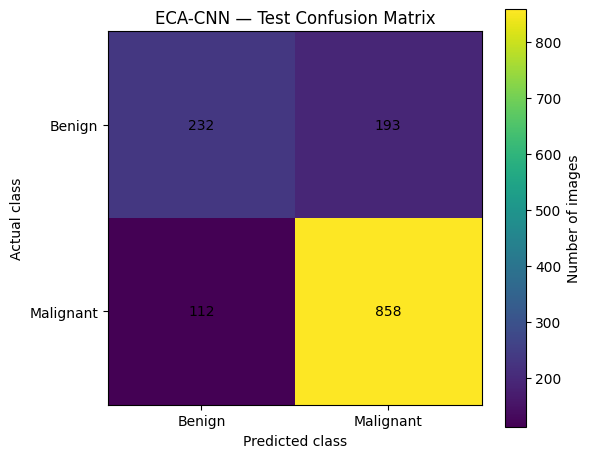

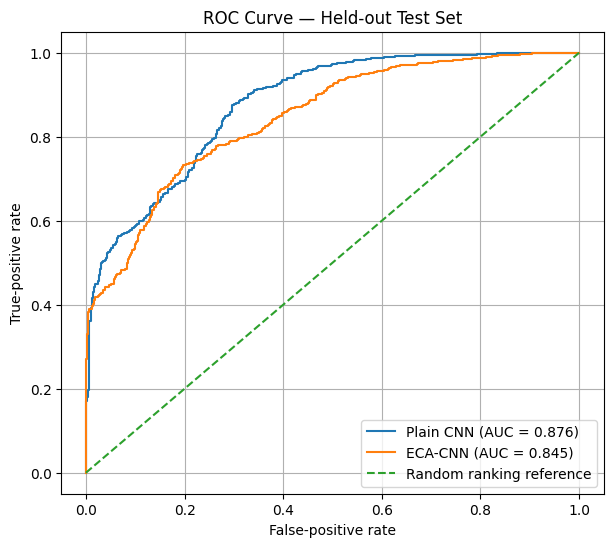

In [14]:
# CELL 14: CONFUSION MATRIX AND ROC CURVE
# ============================================================
# PROJECT PURPOSE:
# Visualize two complementary aspects of classification performance:
# discrete classification errors and probability-based discrimination.
#
# FUNCTIONALITY:
# Confusion matrix:
# - True negatives: benign cases predicted benign.
# - False positives: benign cases predicted malignant.
# - False negatives: malignant cases predicted benign.
# - True positives: malignant cases predicted malignant.
#
# ROC curve:
# - Plots true-positive rate against false-positive rate.
# - Uses multiple probability thresholds.
# - AUC summarizes the curve into a single ranking measure.
#
# RESEARCH CONNECTION:
# These plots support our model evaluation and comparison.
# They are not evidence of clinical validity on their own.

# Create a confusion matrix for the ECA-CNN test predictions.
cm = confusion_matrix(
    y_true_eca,
    eca_preds,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("ECA-CNN — Test Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.xticks([0, 1], ["Benign", "Malignant"])
plt.yticks([0, 1], ["Benign", "Malignant"])

# Print each cell's count directly on the plot.
for row in range(2):
    for col in range(2):
        plt.text(
            col,
            row,
            str(cm[row, col]),
            ha="center",
            va="center"
        )

plt.colorbar(label="Number of images")
plt.tight_layout()
plt.show()


# Plot ROC curves for both models on the same held-out test examples.
plt.figure(figsize=(7, 6))

for model_name, probabilities in [
    ("Plain CNN", baseline_probs),
    ("ECA-CNN", eca_probs)
]:
    # Calculate false-positive and true-positive rates at different
    # thresholds. The test labels are shared across both models.
    fpr, tpr, thresholds = roc_curve(
        y_true,
        probabilities
    )

    # Calculate the area under this model's ROC curve.
    auc_value = roc_auc_score(
        y_true,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

# The diagonal is the reference for random ranking.
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking reference"
)

plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("ROC Curve — Held-out Test Set")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# EVALUATE the ECA-CNN by MAGNIFICATION
# CELL 15: MAGNIFICATION-WISE MODEL EVALUATION
# ============================================================
# PROJECT PURPOSE:
# Examine whether ECA-CNN performance differs across image
# magnification levels, such as 40x, 100x, 200x and 400x.
#
# WHY IS THIS RELEVANT?
# Magnification changes the visual scale of tissue structures.
# A model may perform differently at different magnifications.
# Reporting only an overall average can conceal these differences.
#
# FUNCTIONALITY:
# 1. Identify test rows belonging to each magnification.
# 2. Select the corresponding predictions and probabilities.
# 3. Calculate metrics separately for each group.
# 4. Display the results as a table.
#
# TECHNICAL REQUIREMENT:
# test_loader uses shuffle=False, so predictions from run_epoch
# remain aligned with the order of test_df.
#
# RESEARCH CONNECTION:
# The baseline paper also examines classification at different
# magnifications. Our table is a separate evaluation of our model;
# it is not automatically a like-for-like reproduction of the
# baseline's per-magnification experiments.

magnification_results = []

# Iterate through the magnification levels represented in the test set.
for magnification in test_df["magnification"].unique():

    # Find the test-row positions for this magnification.
    indices = np.flatnonzero(
        test_df["magnification"].to_numpy()
        == magnification
    )

    # Select actual labels and model probabilities for these rows.
    subset_labels = y_true_eca[indices]
    subset_probs = eca_probs[indices]

    # Apply the same fixed decision threshold used in the overall comparison.
    subset_preds = (
        subset_probs >= 0.5
    ).astype(int)

    # Compute ROC-AUC only when both classes are present in this subgroup.
    if len(np.unique(subset_labels)) == 2:
        subset_auc = roc_auc_score(
            subset_labels,
            subset_probs
        )
    else:
        subset_auc = np.nan

    magnification_results.append({
        "Magnification": magnification,
        "Number of images": len(indices),
        "Accuracy": accuracy_score(
            subset_labels,
            subset_preds
        ),
        "Malignant sensitivity": recall_score(
            subset_labels,
            subset_preds,
            pos_label=1,
            zero_division=0
        ),
        "Benign specificity": recall_score(
            subset_labels,
            subset_preds,
            pos_label=0,
            zero_division=0
        ),
        "F1-score": f1_score(
            subset_labels,
            subset_preds,
            zero_division=0
        ),
        "ROC-AUC": subset_auc
    })

# Present magnification-specific results for interpretation.
magnification_table = pd.DataFrame(
    magnification_results
)

display(magnification_table.round(4))

,Magnification,Number of images,Accuracy,Malignant sensitivity,Benign specificity,F1-score,ROC-AUC
0,100,373,0.8097,0.8642,0.6759,0.8658,0.8593
1,200,345,0.7942,0.8898,0.5872,0.8554,0.8616
2,400,311,0.8199,0.8884,0.6667,0.8721,0.8572
3,40,366,0.7077,0.8976,0.2768,0.8099,0.8110


In [16]:
# ============================================================
# CELL 16: GRAD-CAM IMPLEMENTATION
# ============================================================
# PROJECT PURPOSE:
# Implement Gradient-weighted Class Activation Mapping (Grad-CAM)
# to visualize spatial regions that influence the ECA-CNN output.
#
# BASELINE CONNECTION:
# Grad-CAM is also used by the selected ECSAnet research paper.
# We adapt it to our custom CNN rather than reproducing ECSAnet.
#
# HOW IT WORKS:
# 1. A forward hook records feature maps from a chosen convolutional layer.
# 2. A backward hook records gradients at that layer.
# 3. Gradients are averaged over spatial positions to estimate
#    the importance of each feature channel.
# 4. Feature maps are combined using these channel weights.
# 5. Negative values are removed and the heatmap is normalized.
#
# INPUT:
# One preprocessed image tensor with shape [1, 3, H, W].
#
# OUTPUT:
# A normalized heatmap with shape [IMAGE_SIZE, IMAGE_SIZE].
#
# LIMITATION:
# Grad-CAM highlights regions influential to the model's output.
# It does not prove that those regions are cancerous or medically
# meaningful, and it is not a pixel-level segmentation mask.

class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.activations = None
        self.gradients = None

        # Register a forward hook to save the selected layer's output.
        self.forward_handle = (
            target_layer.register_forward_hook(
                self._save_activations
            )
        )

        # Register a backward hook to capture gradients at the layer.
        self.backward_handle = (
            target_layer.register_full_backward_hook(
                self._save_gradients
            )
        )

    def _save_activations(self, module, inputs, output):

        # Save feature maps generated during the forward pass.
        self.activations = output

    def _save_gradients(self, module, grad_input, grad_output):

        # grad_output[0] contains gradients with respect to the layer output.
        self.gradients = grad_output[0]

    def generate(self, image_tensor):

        # Evaluation mode controls layer behavior but does not prevent
        # gradient computation. Grad-CAM requires gradients.
        self.model.eval()
        self.model.zero_grad()

        # Forward pass for one image.
        logit = self.model(image_tensor)

        # Backpropagate the malignant-class logit.
        # This reveals how the selected output depends on the
        # target convolutional layer's activations.
        logit.sum().backward()

        # Fail clearly if the hooks did not capture the required tensors.
        if self.activations is None or self.gradients is None:
            raise RuntimeError(
                "Grad-CAM hooks did not capture activations and gradients."
            )

        # Average gradients over height and width to estimate the
        # relative importance of each feature channel.
        channel_weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Weight each feature map by its channel importance and sum
        # across channels to obtain a spatial activation map.
        cam = (
            channel_weights * self.activations
        ).sum(dim=1, keepdim=True)

        # Retain positive contributions and resize to image resolution.
        cam = torch.relu(cam)

        cam = F.interpolate(
            cam,
            size=(IMAGE_SIZE, IMAGE_SIZE),
            mode="bilinear",
            align_corners=False
        )

        # Select the heatmap for the single image in this batch.
        cam = cam[0, 0]

        # Normalize values to [0, 1] for consistent display.
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        # Convert the heatmap to a NumPy array for plotting.
        return cam.detach().cpu().numpy()

    def close(self):

        # Remove hooks when the explanation is complete.
        # This prevents unnecessary hook retention if repeated images
        # are explained later.
        self.forward_handle.remove()
        self.backward_handle.remove()

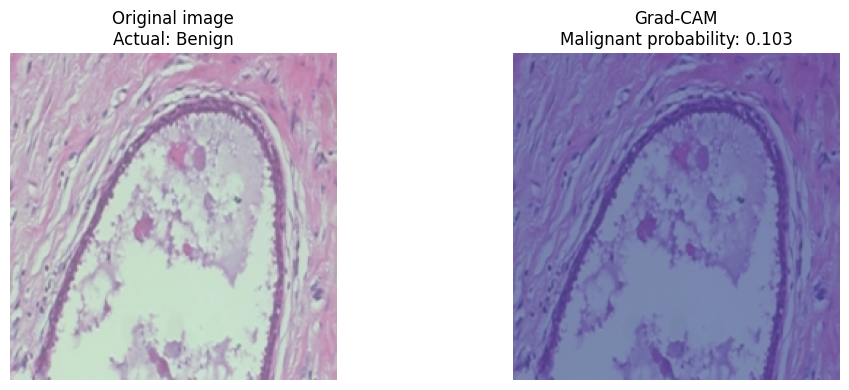

Image path: C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis_v1\histology_slides\breast\benign\SOB\adenosis\SOB_B_A_14-22549AB\100X\SOB_B_A-14-22549AB-100-001.png
Actual class: Benign
Malignant probability: 0.1027


In [17]:
# GENERATE a Grad-CAM EXPLANATION
# CELL 17: VISUALIZE AN ECA-CNN PREDICTION WITH GRAD-CAM
# ============================================================
# PROJECT PURPOSE:
# Demonstrate how Grad-CAM explains a prediction from our
# trained ECA-CNN on a held-out test image.
#
# FUNCTIONALITY:
# 1. Select a test image.
# 2. Identify the final convolutional layer as the explanation target.
# 3. Generate a Grad-CAM heatmap.
# 4. Reverse image normalization for display.
# 5. Overlay the heatmap on the original image.
# 6. Print the predicted probability and actual label.
#
# WHY THE LAST CONVOLUTIONAL LAYER?
# It retains spatial feature maps while representing relatively
# high-level features used by the classifier.
#
# RESEARCH CONNECTION:
# The baseline also uses Grad-CAM, but our heatmap is generated
# from our own trained ECA-CNN architecture.

# Select the first image from the held-out test dataset.
sample_image, sample_label = test_dataset[0]

# Add a batch dimension, changing [3, H, W] to [1, 3, H, W].
sample_batch = sample_image.unsqueeze(0).to(DEVICE)

# Target the final convolutional layer of the ECA-CNN.
gradcam = GradCAM(
    eca_model,
    eca_model.block3.conv
)

# Generate the heatmap and remove the hooks afterward.
heatmap = gradcam.generate(sample_batch)
gradcam.close()

# Obtain the model's malignant-class probability.
# no_grad is appropriate here because this is ordinary inference,
# not the gradient-based Grad-CAM operation above.
with torch.no_grad():
    sample_logit = eca_model(sample_batch)
    sample_probability = torch.sigmoid(sample_logit).item()

# Convert the normalized tensor back to displayable RGB values.
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_display = sample_image.permute(1, 2, 0).numpy()
image_display = np.clip(
    image_display * std + mean,
    0,
    1
)

# Plot the original test image.
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_display)
plt.title(
    f"Original image\nActual: {CLASS_NAMES[int(sample_label.item())]}"
)
plt.axis("off")

# Plot the heatmap over the original image.
plt.subplot(1, 2, 2)
plt.imshow(image_display)
plt.imshow(
    heatmap,
    cmap="jet",
    alpha=0.4
)
plt.title(
    f"Grad-CAM\nMalignant probability: {sample_probability:.3f}"
)
plt.axis("off")

plt.tight_layout()
plt.show()

# Save the sample metadata for the downstream demonstration.
sample_row = test_df.iloc[0]

print("Image path:", sample_row["path"])
print("Actual class:", CLASS_NAMES[int(sample_label.item())])
print("Malignant probability:", round(sample_probability, 4))

In [18]:
# BUILD the TIER 2 SUPERVISORY AGENT
# CELL 18: TIER 2 RULE-BASED SUPERVISORY AGENT
# ============================================================
# PROJECT PURPOSE:
# Implement the second tier of our proposed system.
#
# TIER 1:
# ECA-CNN predicts benign versus malignant and supplies a probability.
#
# TIER 1 EXPLAINABILITY:
# Grad-CAM supplies a visual explanation of the model output.
#
# TIER 2:
# This rule-based agent checks the confidence of the predicted class
# and whether an explanation was generated. It returns a structured
# report and flags cases that meet the configured review conditions.
#
# FUNCTIONALITY:
# - Convert malignant probability into a predicted class.
# - Calculate confidence in that predicted class.
# - Check confidence against a configurable threshold.
# - Check whether Grad-CAM is available.
# - Record review reasons.
# - Return a structured decision-support report.
#
# RESEARCH CONTRIBUTION:
# This supervisory component is our proposed extension; it is not
# the central ECSAnet classification architecture.
#
# SAFETY LIMITATION:
# The agent cannot establish medical correctness. Its threshold is
# an engineering rule, not a clinically validated decision boundary.
# It does not prescribe treatment or replace a pathologist.

class SupervisoryDecisionAgent:

    def __init__(self, confidence_threshold=0.65):

        # Store the rule threshold.
        # This initial value is illustrative and must be justified
        # or tuned using validation data before final reporting.
        self.confidence_threshold = confidence_threshold

    def review(
        self,
        malignant_probability,
        gradcam_available=True
    ):

        # The binary decision uses a probability threshold of 0.5.
        predicted_class = int(
            malignant_probability >= 0.5
        )

        # Confidence is the probability assigned to the selected class.
        # For example, if P(malignant)=0.80, predicted-class confidence
        # is 0.80. If P(malignant)=0.20, confidence in benign is 0.80.
        confidence = max(
            malignant_probability,
            1 - malignant_probability
        )

        # Keep a record of every rule that triggers a review.
        review_reasons = []

        # Low confidence means the model's preferred class is not
        # sufficiently separated from the alternative under this rule.
        if confidence < self.confidence_threshold:
            review_reasons.append(
                "Prediction confidence below configured threshold"
            )

        # A missing heatmap prevents the intended explanation from
        # being included in the report.
        if not gradcam_available:
            review_reasons.append(
                "Grad-CAM explanation unavailable"
            )

        # Route cases with triggered rules for expert review.
        if review_reasons:
            status = "EXPERT REVIEW REQUIRED"
        else:
            status = (
                "PROVISIONAL MODEL OUTPUT — "
                "NOT A CLINICAL DIAGNOSIS"
            )

        # Return a structured report that can be saved or displayed.
        return {
            "predicted_class": CLASS_NAMES[predicted_class],
            "malignant_probability": round(
                float(malignant_probability), 4
            ),
            "prediction_confidence": round(
                float(confidence), 4
            ),
            "gradcam_available": bool(gradcam_available),
            "supervisory_status": status,
            "review_reasons": review_reasons
        }


# Instantiate the supervisory agent using the initial demonstration threshold.
agent = SupervisoryDecisionAgent(
    confidence_threshold=0.65
)

# Pass Tier 1's prediction and explanation availability to Tier 2.
supervisory_report = agent.review(
    malignant_probability=sample_probability,
    gradcam_available=True
)

# Display the report for inspection.
for key, value in supervisory_report.items():
    print(f"{key}: {value}")

predicted_class: Benign
malignant_probability: 0.1027
prediction_confidence: 0.8973
gradcam_available: True
supervisory_status: PROVISIONAL MODEL OUTPUT — NOT A CLINICAL DIAGNOSIS
review_reasons: []


In [19]:
# Part 4 — Confidence analysis, complete inference and research reporting
# Connect Tier 1 and Tier 2 into one workflow
# CELL 19: INTEGRATED TWO-TIER INFERENCE PIPELINE
# ============================================================
# PROJECT PURPOSE:
# Connect the trained ECA-CNN and the supervisory agent into
# one reusable inference function.
#
# FUNCTIONALITY:
# 1. Accept one preprocessed image tensor.
# 2. Generate the Tier 1 malignant probability.
# 3. Generate a Grad-CAM explanation when requested.
# 4. Pass the probability and explanation availability to Tier 2.
# 5. Return the probability, heatmap and supervisory report.
#
# INPUT:
# image_tensor must have shape [1, 3, IMAGE_SIZE, IMAGE_SIZE]
# and must already use the same preprocessing as evaluation images.
#
# OUTPUT:
# - Malignant-class probability.
# - Optional Grad-CAM heatmap.
# - Structured Tier 2 supervisory report.
#
# RESEARCH CONNECTION:
# This integration is the central architectural extension of our
# project. It combines classification, explainability and rule-based
# review routing; the baseline paper's classifier is not being
# represented as having this same supervisory agent.

def run_two_tier_pipeline(
    image_tensor,
    model,
    supervisory_agent,
    generate_explanation=True
):

    # Put the model in evaluation mode to disable training-specific behavior.
    model.eval()

    # Move the image to the same device as the trained model.
    image_tensor = image_tensor.to(DEVICE)

    # Generate the Tier 1 prediction without retaining a computation graph.
    with torch.no_grad():
        logit = model(image_tensor)
        malignant_probability = torch.sigmoid(logit).item()

    # Prepare defaults so the function can report whether an explanation
    # was requested and successfully generated.
    heatmap = None
    gradcam_available = False

    if generate_explanation:

        # Create Grad-CAM for the selected convolutional layer.
        explanation_engine = GradCAM(
            model,
            model.block3.conv
        )

        try:
            # Grad-CAM needs gradients, so generate() runs outside no_grad.
            heatmap = explanation_engine.generate(image_tensor)
            gradcam_available = True

        finally:
            # Always remove the hooks, even if explanation generation fails.
            explanation_engine.close()

    # Tier 2 receives the probability and whether the explanation exists.
    report = supervisory_agent.review(
        malignant_probability=malignant_probability,
        gradcam_available=gradcam_available
    )

    # Return every component needed for display or saving.
    return {
        "malignant_probability": malignant_probability,
        "heatmap": heatmap,
        "gradcam_available": gradcam_available,
        "supervisory_report": report
    }


# Demonstrate the complete pipeline on the previously selected test image.
pipeline_result = run_two_tier_pipeline(
    image_tensor=sample_batch,
    model=eca_model,
    supervisory_agent=agent,
    generate_explanation=True
)

print("Tier 1 malignant probability:",
      round(pipeline_result["malignant_probability"], 4))

print("Grad-CAM available:",
      pipeline_result["gradcam_available"])

print("\nTier 2 supervisory report:")
for key, value in pipeline_result["supervisory_report"].items():
    print(f"{key}: {value}")

Tier 1 malignant probability: 0.1027
Grad-CAM available: True

Tier 2 supervisory report:
predicted_class: Benign
malignant_probability: 0.1027
prediction_confidence: 0.8973
gradcam_available: True
supervisory_status: PROVISIONAL MODEL OUTPUT — NOT A CLINICAL DIAGNOSIS
review_reasons: []


,Confidence threshold,Total validation cases,Accepted cases,Review cases,Coverage,Review rate,Accepted-case accuracy,Accepted-case malignant sensitivity
0,0.50,961,961,0,1.0000,0.0000,0.9074,0.9220
1,0.55,961,917,44,0.9542,0.0458,0.9291,0.9421
2,0.60,961,879,82,0.9147,0.0853,0.9408,0.9489
3,0.65,961,805,156,0.8377,0.1623,0.9491,0.9525
4,0.70,961,760,201,0.7908,0.2092,0.9605,0.9635
5,0.75,961,692,269,0.7201,0.2799,0.9769,0.9789
6,0.80,961,621,340,0.6462,0.3538,0.9855,0.9831
7,0.90,961,477,484,0.4964,0.5036,0.9979,0.9972


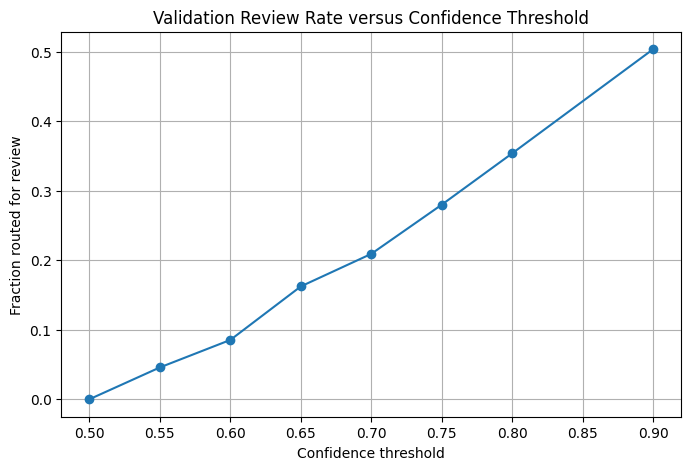

In [20]:
# Analyse the confidence threshold using validation data
# CELL 20: VALIDATION-BASED CONFIDENCE THRESHOLD ANALYSIS
# ============================================================
# PROJECT PURPOSE:
# Study how the Tier 2 confidence threshold changes the number of
# cases routed for expert review.
#
# WHY THIS MATTERS:
# A very high confidence threshold may route many cases for review.
# A very low threshold may allow more provisional outputs, including
# predictions where the model is uncertain.
#
# FUNCTIONALITY:
# 1. Obtain probabilities from the validation set.
# 2. Convert each probability into a predicted class.
# 3. Calculate confidence in that predicted class.
# 4. Examine candidate thresholds.
# 5. Report coverage and review-routing rates.
#
# DEFINITIONS:
# Coverage = fraction of cases whose confidence meets the threshold.
# Review rate = fraction of cases whose confidence falls below it.
#
# RESEARCH CONNECTION:
# This analyses our proposed supervisory agent, not a feature claimed
# as part of the ECSAnet baseline.
#
# IMPORTANT:
# Use validation data for threshold decisions. Do not select a
# threshold based on the test results and then report those same
# test results as an unbiased final evaluation.

# Calculate validation probabilities using the trained ECA-CNN.
_, val_labels, val_probabilities = run_epoch(
    eca_model,
    val_loader
)

# Confidence in the predicted class is max(P(benign), P(malignant)).
val_predictions = (
    val_probabilities >= 0.5
).astype(int)

val_confidence = np.maximum(
    val_probabilities,
    1 - val_probabilities
)

threshold_results = []

# Compare several illustrative thresholds.
# These candidates are for analysis; they are not clinical standards.
candidate_thresholds = [
    0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.90
]

for threshold in candidate_thresholds:

    # A case is provisionally accepted when confidence meets the threshold.
    accepted = val_confidence >= threshold

    # A case is routed for review when it fails the confidence rule.
    sent_for_review = ~accepted

    # Calculate classification performance among accepted cases.
    # This helps show the trade-off between coverage and performance.
    if accepted.any():

        accepted_accuracy = accuracy_score(
            val_labels[accepted],
            val_predictions[accepted]
        )

        accepted_malignant_sensitivity = recall_score(
            val_labels[accepted],
            val_predictions[accepted],
            pos_label=1,
            zero_division=0
        )

    else:
        accepted_accuracy = np.nan
        accepted_malignant_sensitivity = np.nan

    threshold_results.append({
        "Confidence threshold": threshold,
        "Total validation cases": len(val_confidence),
        "Accepted cases": int(accepted.sum()),
        "Review cases": int(sent_for_review.sum()),
        "Coverage": float(accepted.mean()),
        "Review rate": float(sent_for_review.mean()),
        "Accepted-case accuracy": accepted_accuracy,
        "Accepted-case malignant sensitivity":
            accepted_malignant_sensitivity
    })

threshold_table = pd.DataFrame(threshold_results)

display(threshold_table.round(4))

# Plot how the review rate changes with the confidence threshold.
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_table["Confidence threshold"],
    threshold_table["Review rate"],
    marker="o"
)

plt.xlabel("Confidence threshold")
plt.ylabel("Fraction routed for review")
plt.title("Validation Review Rate versus Confidence Threshold")
plt.grid(True)
plt.show()

Malignant probability: 0.9748
Grad-CAM available: True

Supervisory report:
predicted_class: Malignant
malignant_probability: 0.9748
prediction_confidence: 0.9748
gradcam_available: True
supervisory_status: PROVISIONAL MODEL OUTPUT — NOT A CLINICAL DIAGNOSIS
review_reasons: []


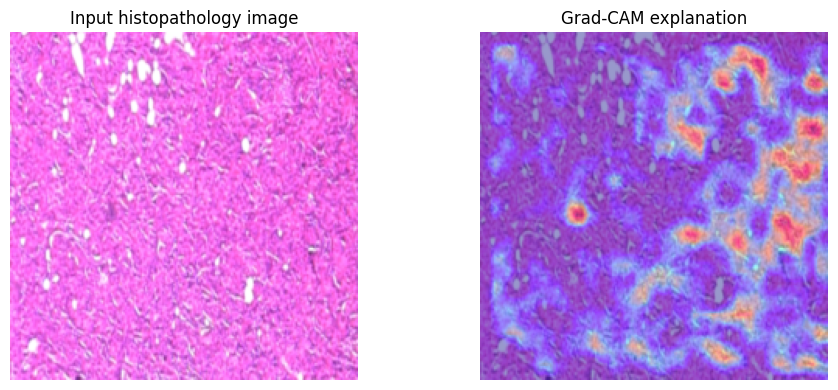

In [21]:
# PERFORM INFERENCE ON A NEW IMAGE.
# CELL 21: SINGLE-IMAGE INFERENCE DEMONSTRATION
# ============================================================
# PROJECT PURPOSE:
# Demonstrate how a new image can pass through the trained ECA-CNN,
# receive a Grad-CAM explanation, and be assessed by Tier 2.
#
# FUNCTIONALITY:
# 1. Load an image selected by its file path.
# 2. Apply evaluation preprocessing.
# 3. Generate a model probability.
# 4. Run the complete two-tier inference pipeline.
# 5. Display the original image and Grad-CAM overlay.
# 6. Print the supervisory report.
#
# INPUT:
# Replace NEW_IMAGE_PATH with a real image file.
# Its dimensions and normalization will be handled by the transform.
#
# IMPORTANT:
# This is a research demonstration. An image must come from a compatible
# source and be prepared appropriately. A high confidence score does
# not establish a clinically correct diagnosis.

NEW_IMAGE_PATH = Path(
    r"C:\Users\Aditya\Downloads\BreaKHis_v1\BreaKHis_v1\histology_slides\breast\malignant\SOB\ductal_carcinoma\SOB_M_DC_14-9461\40X\SOB_M_DC-14-9461-40-026.png"
)

if not NEW_IMAGE_PATH.is_file():
    raise FileNotFoundError(
        f"Image not found: {NEW_IMAGE_PATH}\n"
        "Set NEW_IMAGE_PATH to an actual image before running this cell."
    )

# Open the image and convert it into RGB.
new_image = Image.open(
    NEW_IMAGE_PATH
).convert("RGB")

# Apply the same deterministic preprocessing used for test images.
new_tensor = eval_transform(new_image)

# Add the batch dimension required by the model.
new_batch = new_tensor.unsqueeze(0)

# Run Tier 1, Grad-CAM and Tier 2.
new_result = run_two_tier_pipeline(
    image_tensor=new_batch,
    model=eca_model,
    supervisory_agent=agent,
    generate_explanation=True
)

print("Malignant probability:",
      round(new_result["malignant_probability"], 4))

print("Grad-CAM available:",
      new_result["gradcam_available"])

print("\nSupervisory report:")
for key, value in new_result["supervisory_report"].items():
    print(f"{key}: {value}")

# Reverse normalization for visualization.
image_display = new_tensor.permute(1, 2, 0).numpy()
image_display = np.clip(
    image_display * std + mean,
    0,
    1
)

# Display the original image and explanation when available.
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_display)
plt.title("Input histopathology image")
plt.axis("off")

plt.subplot(1, 2, 2)

if new_result["heatmap"] is not None:
    plt.imshow(image_display)
    plt.imshow(
        new_result["heatmap"],
        cmap="jet",
        alpha=0.4
    )
    plt.title("Grad-CAM explanation")
else:
    plt.imshow(image_display)
    plt.title("Explanation unavailable")

plt.axis("off")
plt.tight_layout()
plt.show()

In [22]:
# OPTIONAL RESNET50 COMPARISON
# CELL 22: OPTIONAL RESNET50 COMPARISON
# ============================================================
# PROJECT PURPOSE:
# Provide an additional established CNN architecture for comparison
# if you have sufficient computing time and memory.
#
# WHY INCLUDE THIS?
# A plain CNN versus ECA-CNN comparison investigates the effect of ECA
# within our custom backbone. ResNet50 provides a different architecture
# reference, which can help contextualize the results.
#
# FUNCTIONALITY:
# - Load ResNet50 architecture.
# - Replace its final classification layer with a single-logit output.
# - Move it to the selected computing device.
#
# LIMITATION:
# This cell only defines the benchmark model. It does not train it.
# To make a fair performance comparison, it must be trained using
# training data, selected using validation data and evaluated once on
# the same held-out test set.
#
# RESEARCH CONNECTION:
# This is an optional additional experiment, not part of the exact
# ECSAnet baseline reproduction.

from torchvision.models import resnet50

# Start with a ResNet50 architecture without pretrained weights.
# This avoids downloading external model weights and keeps initialization
# conditions explicit. It also means the model must learn from our dataset.
resnet_model = resnet50(weights=None)

# Replace the 1000-class ImageNet head with a one-logit binary head.
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    1
)

# Move the benchmark model to the same device.
resnet_model = resnet_model.to(DEVICE)

print("ResNet50 benchmark initialized.")
print(
    "Trainable parameters:",
    sum(
        parameter.numel()
        for parameter in resnet_model.parameters()
        if parameter.requires_grad
    )
)

print(
    "Note: the model is initialized but has not been trained or evaluated."
)

ResNet50 benchmark initialized.
Trainable parameters: 23510081
Note: the model is initialized but has not been trained or evaluated.


In [23]:
# SAVE MODELS, METRICS AND EXPERIMENTAL ARTIFACTS.
# CELL 23: SAVE THE EXPERIMENT RESULTS
# ============================================================
# PROJECT PURPOSE:
# Save trained model weights and evaluation outputs so that
# the experiment can be inspected, reused and documented.
#
# FUNCTIONALITY:
# - Create a project output directory.
# - Save the plain CNN and ECA-CNN state dictionaries.
# - Save the comparison metrics.
# - Save magnification-wise and confidence-threshold tables.
# - Save training histories.
# - Save the exact manifest partitions used in this run.
#
# WHY SAVE THESE ARTIFACTS?
# Research conclusions should be traceable to the models and
# data partitions that generated them. CSV files are also useful
# when preparing tables for a report or presentation.
#
# IMPORTANT:
# The CSV manifests contain local image paths. Moving them to
# another computer may require updating those paths.
# Model weights alone do not record every experimental setting.

OUTPUT_DIR = Path("eca_grad_project_outputs")

# Create the output folder if it does not already exist.
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save learned parameters, not the entire Python model object.
# The architecture class must still be defined to reload these weights.
torch.save(
    baseline_model.state_dict(),
    OUTPUT_DIR / "plain_cnn_weights.pth"
)

torch.save(
    eca_model.state_dict(),
    OUTPUT_DIR / "eca_cnn_weights.pth"
)

# Save overall evaluation results and magnification analysis.
comparison.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

magnification_table.to_csv(
    OUTPUT_DIR / "magnification_metrics.csv",
    index=False
)

# Save validation-based threshold analysis.
threshold_table.to_csv(
    OUTPUT_DIR / "confidence_threshold_analysis.csv",
    index=False
)

# Save the loss histories for training-curve reproduction.
baseline_history.to_csv(
    OUTPUT_DIR / "plain_cnn_training_history.csv",
    index=False
)

eca_history.to_csv(
    OUTPUT_DIR / "eca_cnn_training_history.csv",
    index=False
)

# Store each split's manifest and add a column identifying the partition.
train_df.assign(
    split="train"
).to_csv(
    OUTPUT_DIR / "train_manifest.csv",
    index=False
)

val_df.assign(
    split="validation"
).to_csv(
    OUTPUT_DIR / "validation_manifest.csv",
    index=False
)

test_df.assign(
    split="test"
).to_csv(
    OUTPUT_DIR / "test_manifest.csv",
    index=False
)

print("Experiment artifacts saved in:")
print(OUTPUT_DIR.resolve())

print("\nSaved files:")
for file_path in sorted(OUTPUT_DIR.iterdir()):
    print("-", file_path.name)

Experiment artifacts saved in:
C:\Users\Aditya\Documents\eca_grad_project_outputs

Saved files:
- confidence_threshold_analysis.csv
- eca_cnn_training_history.csv
- eca_cnn_weights.pth
- magnification_metrics.csv
- model_comparison.csv
- plain_cnn_training_history.csv
- plain_cnn_weights.pth
- test_manifest.csv
- train_manifest.csv
- validation_manifest.csv


In [24]:
#ADDITIONAL RESEARCH EVALUATION AND REPORTING (NEW)
#The following cells extend the existing plain-CNN/ECA-CNN experiment. They do not replace the original training, patient-wise split, confusion matrix, ROC, magnification analysis, Grad-CAM or Tier-2 agent.
#- 95% confidence intervals: patient-cluster bootstrap, resampling patients rather than individual images.
# AUPRC: Average Precision for malignant class as the positive class.
# Calibration: Brier score, expected calibration error (ECE), and reliability diagram.
# SHAP: optional GradientExplainer output in addition to the already implemented Grad-CAM.
# Ethics/licensing/code declarations: fields that must be completed with verified institutional and repository information.

,Model,AUROC,AUPRC,Brier score,ECE (10 bins)
0,Plain CNN,0.8762,0.9392,0.1230,NaN
1,ECA-CNN,0.8449,0.9275,0.1441,0.0438


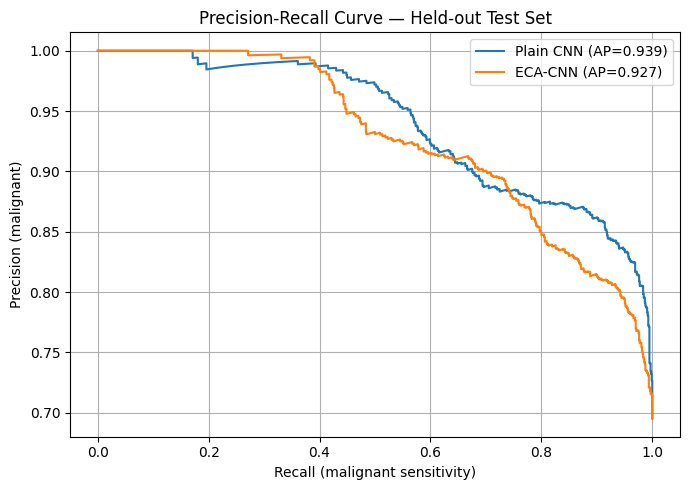

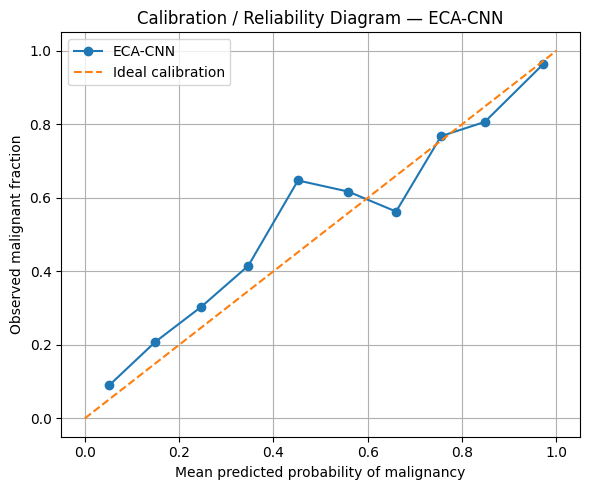

,Bin lower,Bin upper,Images in bin,Mean predicted malignant probability,Observed malignant fraction
0,0.0,0.1,67,0.0514,0.0896
1,0.1,0.2,77,0.1492,0.2078
2,0.2,0.3,79,0.2472,0.3038
3,0.3,0.4,53,0.3466,0.4151
4,0.4,0.5,68,0.4519,0.6471
5,0.5,0.6,107,0.5586,0.6168
6,0.6,0.7,128,0.6600,0.5625
7,0.7,0.8,185,0.7554,0.7676
8,0.8,0.9,191,0.8480,0.8063
9,0.9,1.0,440,0.9721,0.9636


In [27]:
# CELL 24: AUPRC, PRECISION-RECALL CURVE AND CALIBRATION
# ------------------------------------------------------
# The ECA-CNN is treated as the proposed model. The plain CNN remains
# the experimental control. The test set is used only after model
# training/checkpoint selection is complete.
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

if len(np.unique(y_true_eca)) != 2:
    raise ValueError("Both classes are required to calculate AUROC/AUPRC.")

# Average Precision is the scalar summary of the precision-recall curve.
eca_auprc = average_precision_score(y_true_eca, eca_probs)
baseline_auprc = average_precision_score(y_true, baseline_probs)

# Calculate calibration metrics for ECA-CNN probabilities.
eca_brier = brier_score_loss(y_true_eca, eca_probs)

def calculate_ece(y_true, probabilities, n_bins=10):
    """Expected calibration error using equal-width probability bins."""
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities).astype(float)
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    rows = []
    for bin_index in range(n_bins):
        lower, upper = bin_edges[bin_index], bin_edges[bin_index + 1]
        if bin_index == n_bins - 1:
            mask = (probabilities >= lower) & (probabilities <= upper)
        else:
            mask = (probabilities >= lower) & (probabilities < upper)
        if np.any(mask):
            confidence = float(probabilities[mask].mean())
            observed = float(y_true[mask].mean())
            fraction = float(mask.mean())
            ece += fraction * abs(confidence - observed)
            rows.append({
                "Bin lower": lower, "Bin upper": upper,
                "Images in bin": int(mask.sum()),
                "Mean predicted malignant probability": confidence,
                "Observed malignant fraction": observed
            })
    return float(ece), pd.DataFrame(rows)

eca_ece, calibration_bins = calculate_ece(y_true_eca, eca_probs, n_bins=10)

additional_metrics = pd.DataFrame([
    {"Model": "Plain CNN", "AUROC": roc_auc_score(y_true, baseline_probs),
     "AUPRC": baseline_auprc, "Brier score": brier_score_loss(y_true, baseline_probs)},
    {"Model": "ECA-CNN", "AUROC": roc_auc_score(y_true_eca, eca_probs),
     "AUPRC": eca_auprc, "Brier score": eca_brier, "ECE (10 bins)": eca_ece}
])
display(additional_metrics.round(4))

# Precision-recall curve for both models.
plt.figure(figsize=(7, 5))
for name, labels, probabilities in [
    ("Plain CNN", y_true, baseline_probs),
    ("ECA-CNN", y_true_eca, eca_probs)
]:
    precision_values, recall_values, _ = precision_recall_curve(labels, probabilities)
    ap = average_precision_score(labels, probabilities)
    plt.plot(recall_values, precision_values, label=f"{name} (AP={ap:.3f})")
plt.xlabel("Recall (malignant sensitivity)")
plt.ylabel("Precision (malignant)")
plt.title("Precision-Recall Curve — Held-out Test Set")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

# Reliability diagram: compare predicted probabilities with observed frequency.
observed_fraction, mean_predicted_probability = calibration_curve(
    y_true_eca, eca_probs, n_bins=10, strategy="uniform"
)
plt.figure(figsize=(6, 5))
plt.plot(mean_predicted_probability, observed_fraction, marker="o", label="ECA-CNN")
plt.plot([0, 1], [0, 1], linestyle="--", label="Ideal calibration")
plt.xlabel("Mean predicted probability of malignancy")
plt.ylabel("Observed malignant fraction")
plt.title("Calibration / Reliability Diagram — ECA-CNN")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

display(calibration_bins.round(4))


In [28]:
# CELL 25: PATIENT-CLUSTER BOOTSTRAP 95% CONFIDENCE INTERVALS
# -------------------------------------------------------------
# test_loader must have shuffle=False so y_true_eca and eca_probs
# are aligned row-for-row with test_df.

def patient_cluster_bootstrap(test_frame, y_true, probabilities,
                              n_bootstrap=2000, random_state=SEED):
    frame = test_frame.reset_index(drop=True).copy()
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities).astype(float)
    if len(frame) != len(y_true) or len(y_true) != len(probabilities):
        raise ValueError("test_df, labels and probabilities are not aligned.")
    if frame["patient_id"].isna().any():
        raise ValueError("Patient IDs are missing; cluster bootstrap cannot be trusted.")

    patient_ids = frame["patient_id"].astype(str).to_numpy()
    unique_patients = np.unique(patient_ids)
    if len(unique_patients) < 5:
        raise ValueError("Fewer than five test patients: cluster-bootstrap intervals are unreliable.")
    patient_rows = {pid: np.flatnonzero(patient_ids == pid) for pid in unique_patients}
    rng = np.random.default_rng(random_state)
    bootstrap_records = []

    for _ in range(n_bootstrap):
        sampled_patients = rng.choice(unique_patients, size=len(unique_patients), replace=True)
        # Concatenating a patient's rows repeatedly correctly represents
        # repeated selection of that patient in a cluster bootstrap.
        sampled_indices = np.concatenate([patient_rows[pid] for pid in sampled_patients])
        labels = y_true[sampled_indices]
        probs = probabilities[sampled_indices]
        predictions = (probs >= 0.5).astype(int)
        if len(np.unique(labels)) < 2:
            continue
        tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
        bootstrap_records.append({
            "Accuracy": accuracy_score(labels, predictions),
            "Precision": precision_score(labels, predictions, zero_division=0),
            "Sensitivity": recall_score(labels, predictions, pos_label=1, zero_division=0),
            "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
            "F1": f1_score(labels, predictions, zero_division=0),
            "AUROC": roc_auc_score(labels, probs),
            "AUPRC": average_precision_score(labels, probs)
        })

    bootstrap_df = pd.DataFrame(bootstrap_records)
    if bootstrap_df.empty:
        raise RuntimeError("No valid bootstrap replicates contained both classes.")

    point_predictions = (probabilities >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, point_predictions, labels=[0, 1]).ravel()
    point_estimates = {
        "Accuracy": accuracy_score(y_true, point_predictions),
        "Precision": precision_score(y_true, point_predictions, zero_division=0),
        "Sensitivity": recall_score(y_true, point_predictions, pos_label=1, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "F1": f1_score(y_true, point_predictions, zero_division=0),
        "AUROC": roc_auc_score(y_true, probabilities),
        "AUPRC": average_precision_score(y_true, probabilities)
    }
    output_rows = []
    for metric_name, estimate in point_estimates.items():
        lower, upper = bootstrap_df[metric_name].quantile([0.025, 0.975]).tolist()
        output_rows.append({
            "Metric": metric_name, "Estimate": estimate,
            "95% CI lower": lower, "95% CI upper": upper,
            "Valid bootstrap replicates": len(bootstrap_df)
        })
    return pd.DataFrame(output_rows), bootstrap_df

ci_table, bootstrap_distribution = patient_cluster_bootstrap(
    test_df, y_true_eca, eca_probs, n_bootstrap=2000, random_state=SEED
)
print("Number of test images:", len(test_df))
print("Number of test patients:", test_df["patient_id"].nunique())
print("Valid bootstrap replicates:", int(ci_table["Valid bootstrap replicates"].iloc[0]))
display(ci_table.round(4))


Number of test images: 1395
Number of test patients: 13
Valid bootstrap replicates: 1978


,Metric,Estimate,95% CI lower,95% CI upper,Valid bootstrap replicates
0,Accuracy,0.7814,0.6393,0.9015,1978
1,Precision,0.8164,0.5780,0.9522,1978
2,Sensitivity,0.8845,0.7567,0.9883,1978
3,Specificity,0.5459,0.1776,0.7330,1978
4,F1,0.8491,0.6862,0.9440,1978
5,AUROC,0.8449,0.6314,0.9582,1978
6,AUPRC,0.9275,0.7738,0.9894,1978


C:\Users\Aditya\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


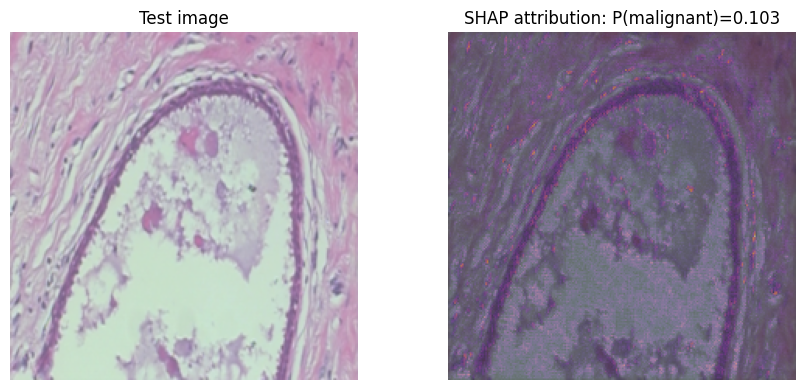

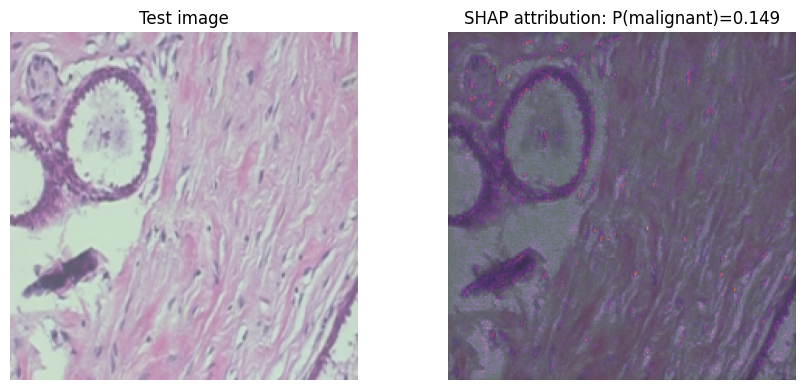

SHAP explanations generated for 2 held-out test images.


In [29]:
# CELL 26: OPTIONAL SHAP GRADIENT EXPLAINER
# -----------------------------------------
# If SHAP is missing, run this once in a separate cell:
# %pip install shap
# Then restart the kernel and run the notebook again.

try:
    import shap
except ImportError as exc:
    raise ImportError("SHAP is not installed. Run: %pip install shap, restart kernel, then rerun.") from exc

class MalignantProbabilityModel(nn.Module):
    """Wrap the one-logit CNN so SHAP explains P(malignant)."""
    def __init__(self, classifier):
        super().__init__()
        self.classifier = classifier
    def forward(self, image_batch):
        return torch.sigmoid(self.classifier(image_batch)).reshape(-1, 1)

shap_model = MalignantProbabilityModel(eca_model).to(DEVICE).eval()

# Background examples are sampled only from the training loader.
background_parts = []
background_count = 0
for image_batch, _ in train_loader:
    background_parts.append(image_batch)
    background_count += len(image_batch)
    if background_count >= 12:
        break
shap_background = torch.cat(background_parts, dim=0)[:12].to(DEVICE)

# Explain up to two images from the held-out test set.
explain_parts = []
explain_count = 0
for image_batch, _ in test_loader:
    explain_parts.append(image_batch)
    explain_count += len(image_batch)
    if explain_count >= 2:
        break
shap_examples = torch.cat(explain_parts, dim=0)[:2].to(DEVICE)

shap_explainer = shap.GradientExplainer(shap_model, shap_background)
shap_values = shap_explainer.shap_values(shap_examples)

# SHAP versions can return either a list or an array.
if isinstance(shap_values, list):
    shap_array = np.asarray(shap_values[0])
else:
    shap_array = np.asarray(shap_values)
# Normalize possible trailing single-output dimension.
if shap_array.ndim == 5 and shap_array.shape[-1] == 1:
    shap_array = shap_array[..., 0]
if shap_array.ndim != 4:
    raise RuntimeError(f"Unexpected SHAP array dimensions: {shap_array.shape}")

# Expected layout is [images, channels, height, width].
for image_index in range(len(shap_examples)):
    attribution = np.mean(np.abs(shap_array[image_index]), axis=0)
    attribution = attribution / (attribution.max() + 1e-8)
    image_np = shap_examples[image_index].detach().cpu().numpy().transpose(1, 2, 0)
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image_np = np.clip(image_np * std + mean, 0, 1)
    with torch.no_grad():
        malignant_prob = float(shap_model(shap_examples[image_index:image_index+1]).item())
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(image_np); axes[0].set_title("Test image")
    axes[1].imshow(image_np); axes[1].imshow(attribution, cmap="inferno", alpha=0.5)
    axes[1].set_title(f"SHAP attribution: P(malignant)={malignant_prob:.3f}")
    for axis in axes: axis.axis("off")
    plt.tight_layout(); plt.show()

print("SHAP explanations generated for", len(shap_examples), "held-out test images.")
